# Признаки и разделение по времени

## Эксперимент B · признаки и временное разделение

Здесь не обучаем модель. Формируем проверяемый кандидат протокола на финальной
выборке A. market_segment не обязателен и не входит в основной кандидатный набор:
его календарная поддержка обрывается в январе 2023. Непустые метаданные и C40
пока не имеют подтвержденного исторического времени получения.

**Статус: ретроспективный протокол с условной доступностью, не эксплуатационная
валидация.** Ни одна будущая переменная не используется как предиктор.

### Зафиксированный дизайн до чтения данных

- Время разделения — C40_CROSS_TIME, а не время посадки.
- Train: C40 с 2019-01-01 до 2022-01-01; validation: 2022 год;
  test: наблюдаемая часть 2023 года. Все границы UTC, справа не включены.
- Перед validation и test оставляем зазор 24 часа. Это исследовательское
  предположение, не доказанная достаточная независимость и не авиационный норматив.
- Чтобы метки предыдущей части не формировались по событиям следующей части,
  запись из train / validation с landing_time или любым attempt_times на границе
  следующего периода либо позже получает статус purge_outcome_boundary.
  Эти будущие даты нужны только для аудита разделения, не для прогноза.
- Проверяем уникальность составного ключа flight_id + icao24 + airport +
  landing_time и повторяемость прокси события icao24 + airport + первый attempt.
  Совпадение прокси требует проверки; оно не доказывает физическую идентичность.
- Один самолет может встречаться в разных периодах: это сценарий будущих событий
  на знакомом парке. Идентификаторы запрещены в признаках; перенос на новый парк
  требует отдельного исследования. Test не используется для выбора настроек.

Границы фиксированы по календарю, а не по достигнутым метрикам или частоте GoA.
Текущая таблица дает время событий, но не время публикации метки: проверка
landing / attempts не доказывает, что метка действительно была получена к cutoff.

In [1]:
from pathlib import Path
import os,hashlib,json
import numpy as np
import pandas as pd
import pyarrow as pa
import pyarrow.parquet as pq
import matplotlib.pyplot as plt
from IPython.display import display,Markdown
ROOT=Path.cwd().resolve()
while not (ROOT/'reports/verification.json').exists():
    if ROOT==ROOT.parent: raise FileNotFoundError('Нет манифеста A')
    ROOT=ROOT.parent
R=ROOT/'reports'; F=ROOT/'figures'; LOCAL=ROOT/'data'; LOCAL.mkdir(exist_ok=True)
manifest=json.loads((R/'verification.json').read_text(encoding='utf-8'))
entry=next(x for x in manifest['inputs'] if x['stage']=='final')
DATA=Path(os.environ.get('SAMPLE_SELECTION_DATA_ROOT',ROOT.parents[1]))/entry['file'].replace(chr(92),'/')
if not DATA.exists(): DATA=LOCAL/'06_05_cases_excluded.parquet'
def sha(path):
    h=hashlib.sha256()
    with path.open('rb') as stream:
        for block in iter(lambda:stream.read(8*1024*1024),b''): h.update(block)
    return h.hexdigest()
assert sha(DATA)==entry['sha256']
plt.rcParams.update({'figure.dpi':120,'font.size':11,'axes.spines.top':False,
 'axes.spines.right':False,'axes.grid':True,'grid.alpha':.18})
def save(name):
    plt.tight_layout()
    for ext in ['png','svg']: plt.savefig(F/f'{name}.{ext}',bbox_inches='tight')
    plt.show()
START=pd.Timestamp('2019-01-01',tz='UTC')
VALID=pd.Timestamp('2022-01-01',tz='UTC'); TEST=pd.Timestamp('2023-01-01',tz='UTC')
GAP=pd.Timedelta(hours=24)
sets={'C40_core':['airport','C40_BEARING','C40_CROSS_LAT','C40_CROSS_LON'],
      'C40_aircraft':['airport','C40_BEARING','C40_CROSS_LAT','C40_CROSS_LON',
                      'typecode','icaoaircrafttype','AC_CLASS']}
contract=pd.read_csv(R/'temporal_field_contract.csv').set_index('field')
allowed={'conditional_event','conditional_context','conditional_metadata'}
assert all(contract.loc[f,'policy'] in allowed for fields in sets.values() for f in fields)
assert all('market_segment' not in fields for fields in sets.values())
feature_rows=[{'set':name,'field':f,'policy':contract.loc[f,'policy'],
 'availability':'не подтверждена исторически','missing_policy':'сохранить запись; обработка fit только на train'}
 for name,fields in sets.items() for f in fields]
pd.DataFrame(feature_rows).to_csv(R/'protocol_feature_sets.csv',index=False)
display(pd.DataFrame(feature_rows))


,set,field,policy,availability,missing_policy
0,C40_core,airport,conditional_context,не подтверждена исторически,сохранить запись; обработка fit только на train
1,C40_core,C40_BEARING,conditional_event,не подтверждена исторически,сохранить запись; обработка fit только на train
2,C40_core,C40_CROSS_LAT,conditional_event,не подтверждена исторически,сохранить запись; обработка fit только на train
3,C40_core,C40_CROSS_LON,conditional_event,не подтверждена исторически,сохранить запись; обработка fit только на train
4,C40_aircraft,airport,conditional_context,не подтверждена исторически,сохранить запись; обработка fit только на train
5,C40_aircraft,C40_BEARING,conditional_event,не подтверждена исторически,сохранить запись; обработка fit только на train
6,C40_aircraft,C40_CROSS_LAT,conditional_event,не подтверждена исторически,сохранить запись; обработка fit только на train
7,C40_aircraft,C40_CROSS_LON,conditional_event,не подтверждена исторически,сохранить запись; обработка fit только на train
8,C40_aircraft,typecode,conditional_metadata,не подтверждена исторически,сохранить запись; обработка fit только на train
9,C40_aircraft,icaoaircrafttype,conditional_metadata,не подтверждена исторически,сохранить запись; обработка fit только на train


## 1. Признаки и единая база сравнения

Оба набора используют одни и те же записи и split. Отсутствующий typecode или
icaoaircrafttype не удаляет наблюдение: будущий препроцессор должен учиться
только на train и иметь отдельные состояния missing / unseen. AC_CLASS остается
сырым кодом до подтверждения словаря. Никакие восстановленные описания самолетов
не подменяют историческое наблюдение.

Из C40_CROSS_TIME в будущем можно получить час суток / день недели UTC;
преобразования определяются заранее. Сам абсолютный timestamp не входит в набор.
Предполагаемый аэропорт, единицы bearing и момент получения C40 требуют проверки.
flight_id, callsign, icao24, registration, ILS, n_attempts, GoA, landing_time,
attempt_times и флаги будущих сравнений не являются признаками.

In [2]:
columns=['flight_id','icao24','airport','landing_time','C40_CROSS_TIME','attempt_times',
         'GoA','typecode','icaoaircrafttype','AC_CLASS']
reader=pq.ParquetFile(DATA); pieces=[]; offset=0
for batch in reader.iter_batches(batch_size=200000,columns=columns):
    d=batch.to_pandas()
    d['first_attempt']=pd.to_datetime(d.attempt_times.map(lambda x:min(x)),utc=True)
    d['last_attempt']=pd.to_datetime(d.attempt_times.map(lambda x:max(x)),utc=True)
    d=d.drop(columns='attempt_times')
    d['source_row']=np.arange(offset,offset+len(d),dtype=np.int64); offset+=len(d)
    t=d.C40_CROSS_TIME
    status=np.select([t.lt(START),t.ge(START)&t.lt(VALID),t.ge(VALID)&t.lt(TEST),t.ge(TEST)],
                     ['before_train','train','validation','test'],default='invalid_time')
    d['split']=pd.Categorical(status,categories=['before_train','train','validation','test','invalid_time',
                                               'embargo','purge_outcome_boundary'])
    train=d.split.eq('train'); valid=d.split.eq('validation')
    outcome_end=d[['landing_time','last_attempt']].max(axis=1)
    purge=(train & outcome_end.ge(VALID)) | (valid & outcome_end.ge(TEST))
    embargo=(train & t.ge(VALID-GAP)) | (valid & t.ge(TEST-GAP))
    # Приоритет: пересечение исхода, затем временной зазор.
    d.loc[embargo,'split']='embargo'; d.loc[purge,'split']='purge_outcome_boundary'
    assert t.notna().all() and (t<d.first_attempt).all()
    pieces.append(d)
del reader
d=pd.concat(pieces,ignore_index=True); del pieces
assert len(d)==entry['rows'] and int(d.GoA.sum())==18349
summary=d.groupby('split',observed=True).agg(rows=('GoA','size'),goa=('GoA','sum'),
 first_c40=('C40_CROSS_TIME','min'),last_c40=('C40_CROSS_TIME','max')).reset_index()
summary['goa_pct']=100*summary.goa/summary.rows
summary.to_csv(R/'protocol_split_summary.csv',index=False); display(summary)


,split,rows,goa,first_c40,last_c40,goa_pct
0,train,4161493,11618,2019-01-01 00:40:34+00:00,2021-12-30 23:58:53+00:00,0.279179
1,validation,1619847,4984,2022-01-01 00:01:25+00:00,2022-12-20 23:35:31+00:00,0.307683
2,test,546577,1739,2023-01-01 00:08:10+00:00,2023-05-30 23:48:15+00:00,0.318162
3,embargo,3567,8,2021-12-31 00:07:20+00:00,2021-12-31 23:41:06+00:00,0.224278
4,purge_outcome_boundary,1,0,2022-12-31 23:45:43+00:00,2022-12-31 23:45:43+00:00,0.000000


## 2. Повторные записи и межпериодные пересечения

Составной ключ проверяем точным сравнением полей, без предположения об уникальности
flight_id и без опоры только на хеш. Число дублированных строк включает все
члены повторной группы. Повторяемость icao24 сама по себе не утечка исхода;
пересечение событий между частями — отдельное препятствие для протокола.

In [3]:
KEY=['flight_id','icao24','airport','landing_time']
EVENT=['icao24','airport','first_attempt']
usable=d[d.split.isin(['train','validation','test'])]
checks=[]
for name,key in [('flight_id',['flight_id']),('composite',KEY),('event_proxy',EVENT)]:
    duplicate=d.duplicated(key,keep=False)
    repeated=usable.groupby(key,observed=True,dropna=False).split.nunique()
    checks.append({'key':name,'duplicate_rows_all':int(duplicate.sum()),
                   'distinct_keys_all':int(d.groupby(key,observed=True,dropna=False).ngroups),
                   'keys_in_multiple_splits':int(repeated.gt(1).sum())})
checks=pd.DataFrame(checks); checks.to_csv(R/'protocol_key_audit.csv',index=False)
display(checks)
overlap=[]
for later,earlier in [('validation',['train']),('test',['train','validation'])]:
    historical=set(usable.loc[usable.split.isin(earlier),'icao24'])
    current=usable[usable.split.eq(later)]
    overlap.append({'split':later,'rows':len(current),'aircraft':current.icao24.nunique(),
      'rows_with_previously_seen_aircraft':int(current.icao24.isin(historical).sum()),
      'previously_seen_aircraft':len(set(current.icao24)&historical)})
pd.DataFrame(overlap).to_csv(R/'protocol_aircraft_overlap.csv',index=False); display(pd.DataFrame(overlap))
airport=usable.groupby(['split','airport'],observed=True).agg(rows=('GoA','size'),goa=('GoA','sum')).reset_index()
airport.to_csv(R/'protocol_airport_coverage.csv',index=False)
monthly=d.assign(month=d.C40_CROSS_TIME.dt.strftime('%Y-%m')).groupby(['month','split'],observed=True).agg(
 rows=('GoA','size'),goa=('GoA','sum')).reset_index()
monthly.to_csv(R/'protocol_month_coverage.csv',index=False)
complete=usable.typecode.notna()&usable.typecode.ne('').fillna(False)&usable.icaoaircrafttype.notna()&usable.icaoaircrafttype.ne('').fillna(False)&usable.AC_CLASS.notna()&usable.AC_CLASS.ne('').fillna(False)
sensitivity=usable.assign(metadata_complete=complete).groupby('split',observed=True).agg(
 rows=('GoA','size'),complete_rows=('metadata_complete','sum')).reset_index()
sensitivity.to_csv(R/'protocol_metadata_completeness.csv',index=False); display(sensitivity)


,key,duplicate_rows_all,distinct_keys_all,keys_in_multiple_splits
0,flight_id,42202,6308535,13005
1,composite,0,6331485,0
2,event_proxy,0,6331485,0


,split,rows,aircraft,rows_with_previously_seen_aircraft,previously_seen_aircraft
0,validation,1619847,11077,1593489,9957
1,test,546577,8493,545994,8291


,split,rows,complete_rows
0,train,4161493,3994239
1,validation,1619847,1532277
2,test,546577,516253


## 3. Видимое покрытие протокола

Test содержит только фактически наблюдаемые даты 2023; его нельзя представлять
как полный год. Частота метки здесь описательная и не использовалась для
подбора границ. Аэропорты с отсутствующим поздним покрытием не получают
искусственный нулевой риск.

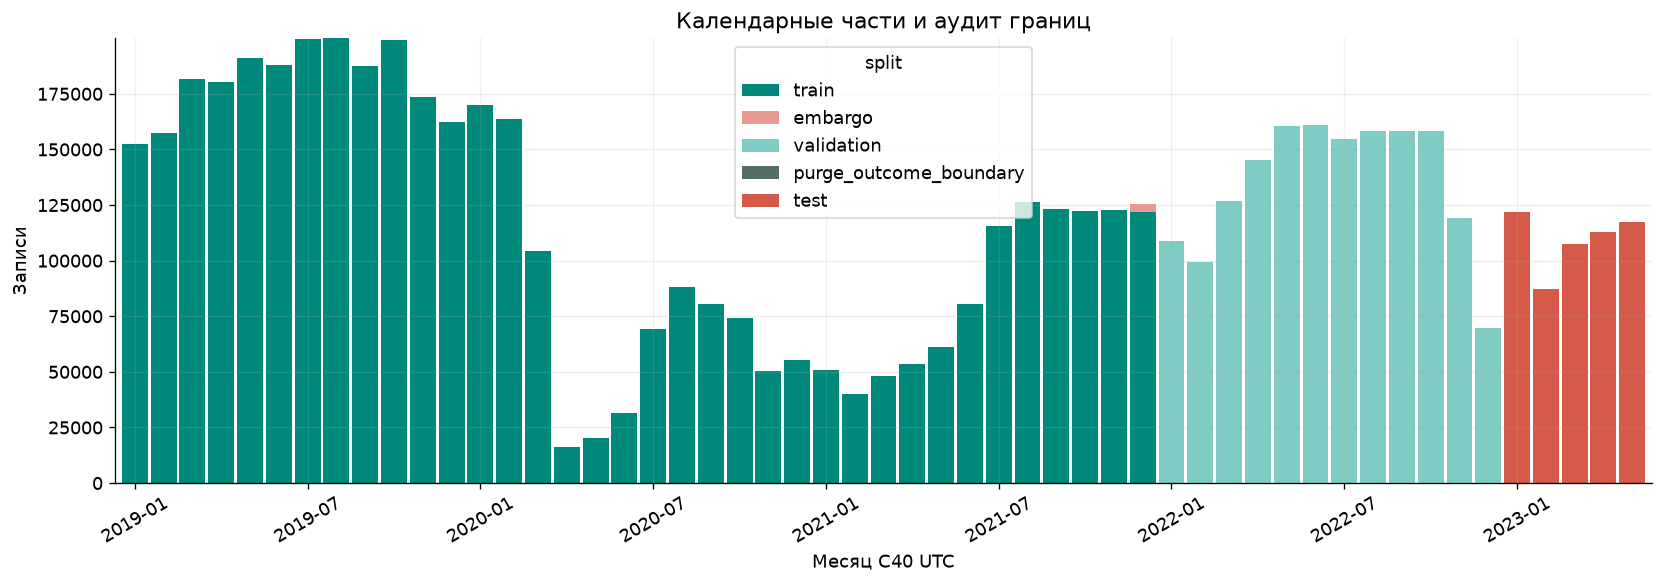

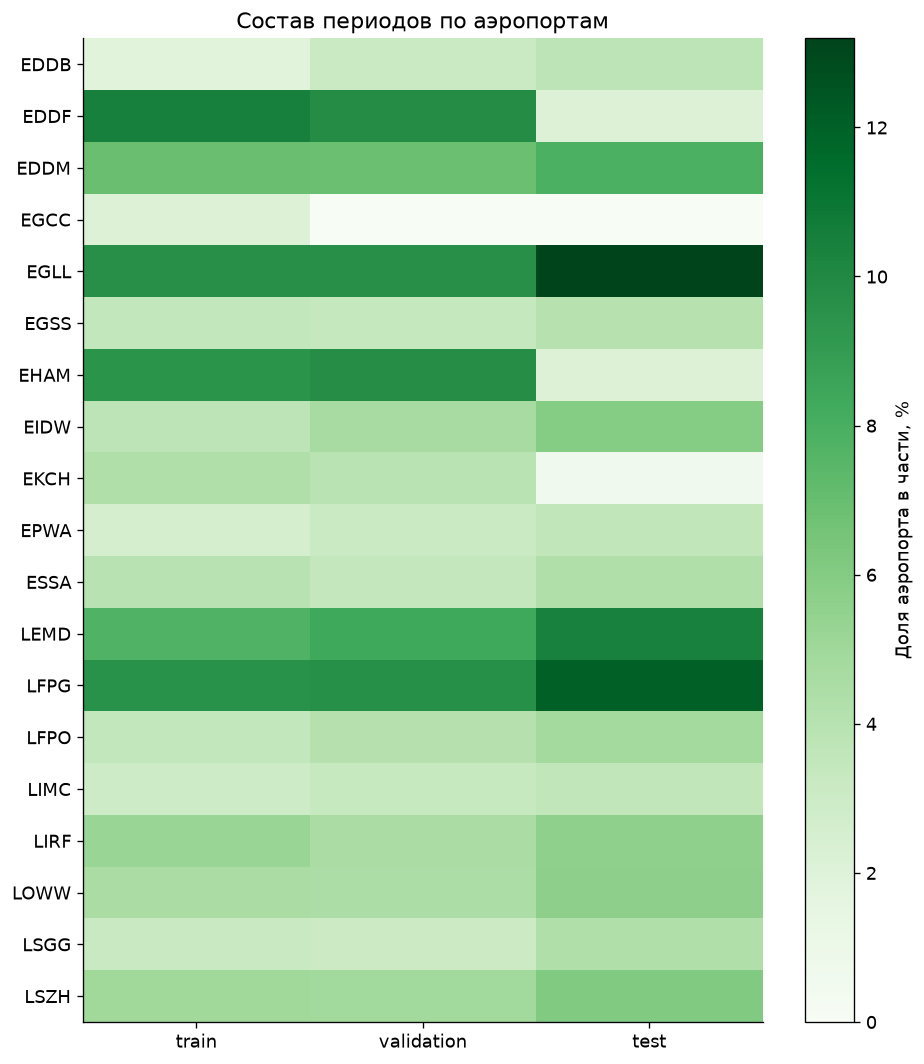

In [4]:
colors={'train':'#00897B','validation':'#80CBC4','test':'#D65A4A',
 'embargo':'#E69A90','purge_outcome_boundary':'#546E63','before_train':'#aaaaaa'}
p=monthly.pivot(index='month',columns='split',values='rows').fillna(0)
p.plot.bar(stacked=True,figsize=(14,5),color=[colors.get(s,'#aaaaaa') for s in p.columns],width=.9)
plt.ylabel('Записи'); plt.xlabel('Месяц C40 UTC'); plt.title('Календарные части и аудит границ')
plt.xticks(range(0,len(p),6),p.index[::6],rotation=30); save('20_protocol_calendar_split')
a=airport.pivot(index='airport',columns='split',values='rows').fillna(0).reindex(columns=['train','validation','test'])
a=a.div(a.sum(axis=0),axis=1)*100
fig,ax=plt.subplots(figsize=(8,9)); im=ax.imshow(a,aspect='auto',cmap='Greens',vmin=0,vmax=float(a.max().max()))
ax.set_yticks(range(len(a)),a.index); ax.set_xticks(range(3),a.columns); ax.grid(False)
fig.colorbar(im,ax=ax,label='Доля аэропорта в части, %'); ax.set_title('Состав периодов по аэропортам')
save('21_protocol_airport_composition')


## 4. Локальная разметка и критерии допуска

Сохраняем порядковый номер строки и split в локальном data/, исключенном из Git.
Эта разметка привязана к SHA256 и порядку строк конкретного parquet. Она не
изменяет исходную аналитическую выборку и не является автоматически принятой
новой схемой исключений.

Для последующего сравнения моделей: единый test для обоих наборов, все
преобразования fit на train, выбор параметров только на validation, test один раз
после фиксации решения. План метрик: PR-AUC, ROC-AUC, Brier score, калибровка и
precision / recall при пороге, выбранном на validation; отдельно по аэропортам.
Интервалы и зависимость наблюдений потребуют заранее выбранного способа
группировки. Метрики в этом ноутбуке не вычисляются.

In [5]:
assert int(summary.rows.sum())==len(d) and int(summary.goa.sum())==int(d.GoA.sum())
assert not d.split.eq('invalid_time').any()
for split,cutoff in [('train',VALID),('validation',TEST)]:
    q=d[d.split.eq(split)]
    assert (q.C40_CROSS_TIME<cutoff-GAP).all()
    assert (q.landing_time<cutoff).all() and (q.last_attempt<cutoff).all()
assert usable.C40_CROSS_TIME.min()>=START
assert sha(DATA)==entry['sha256']
event_overlap=int(checks.set_index('key').loc['event_proxy','keys_in_multiple_splits'])
composite_unique=int(checks.set_index('key').loc['composite','duplicate_rows_all'])==0
label_path=LOCAL/'06_candidate_split_labels.parquet'
pq.write_table(pa.Table.from_pandas(d[['source_row','split']],preserve_index=False),label_path,compression='zstd')
protocol={'input_sha256':entry['sha256'],'split_file_sha256':sha(label_path),
 'time_field':'C40_CROSS_TIME','train_start':str(START),'validation_start':str(VALID),
 'test_start':str(TEST),'embargo_hours':24,'boundary_purge':'landing_time or last attempt >= next cutoff',
 'feature_sets':sets,'calendar_features_planned':['UTC hour cyclic','UTC day of week'],
 'missing_metadata_drops_rows':False,'rows':len(d),'goa':int(d.GoA.sum()),
 'balances_passed':True,'input_unchanged':True,'composite_key_unique':composite_unique,
 'event_proxy_cross_split_keys':event_overlap,'operational_availability_verified':False,
 'training_performed':False,'status':'candidate_retrospective_protocol',
 'structural_checks_passed':composite_unique and event_overlap==0}
(R/'protocol_manifest.json').write_text(json.dumps(protocol,ensure_ascii=False,indent=2),encoding='utf-8')
text=f"""# Кандидат протокола временного разделения

Временные части UTC рассчитаны на C40; embargo 24 часа и purge исходов на
границе — исследовательские решения. База A не изменялась.

{summary.to_string(index=False)}

{checks.to_string(index=False)}

Составной ключ уникален: {composite_unique}. Пересекающихся прокси событий:
{event_overlap}. Структурные проверки пройдены: {protocol['structural_checks_passed']}.
Даже при успешных структурных проверках историческая доступность признаков и
меток не доказана; обучение и эксплуатационная готовность не заявляются.
Оба кандидатных набора сохраняют записи с пропусками метаданных и исключают
market_segment. Набор AC_CLASS требует словаря кодов. Идентификаторы в признаки
не входят. Наблюдаемый test — неполный 2023 год; позднее покрытие аэропортов
нужно учитывать при формулировке области применимости.

Локальная разметка строк записана в data/06_candidate_split_labels.parquet,
не распространяется через Git и действительна только для указанного SHA256.
Следующий шаг перед обучением: подтвердить / ограничить контракт доступности,
проверить повторные прокси событий при наличии и зафиксировать обработку
категорий и план оценки. Этот протокол не дает автоматического разрешения
запускать основное GoA-обучение.
"""
(R/'protocol_findings.md').write_text(text,encoding='utf-8'); display(Markdown(text))


# Кандидат протокола временного разделения

Временные части UTC рассчитаны на C40; embargo 24 часа и purge исходов на
границе — исследовательские решения. База A не изменялась.

                 split    rows   goa                 first_c40                  last_c40  goa_pct
                 train 4161493 11618 2019-01-01 00:40:34+00:00 2021-12-30 23:58:53+00:00 0.279179
            validation 1619847  4984 2022-01-01 00:01:25+00:00 2022-12-20 23:35:31+00:00 0.307683
                  test  546577  1739 2023-01-01 00:08:10+00:00 2023-05-30 23:48:15+00:00 0.318162
               embargo    3567     8 2021-12-31 00:07:20+00:00 2021-12-31 23:41:06+00:00 0.224278
purge_outcome_boundary       1     0 2022-12-31 23:45:43+00:00 2022-12-31 23:45:43+00:00 0.000000

        key  duplicate_rows_all  distinct_keys_all  keys_in_multiple_splits
  flight_id               42202            6308535                    13005
  composite                   0            6331485                        0
event_proxy                   0            6331485                        0

Составной ключ уникален: True. Пересекающихся прокси событий:
0. Структурные проверки пройдены: True.
Даже при успешных структурных проверках историческая доступность признаков и
меток не доказана; обучение и эксплуатационная готовность не заявляются.
Оба кандидатных набора сохраняют записи с пропусками метаданных и исключают
market_segment. Набор AC_CLASS требует словаря кодов. Идентификаторы в признаки
не входят. Наблюдаемый test — неполный 2023 год; позднее покрытие аэропортов
нужно учитывать при формулировке области применимости.

Локальная разметка строк записана в data/06_candidate_split_labels.parquet,
не распространяется через Git и действительна только для указанного SHA256.
Следующий шаг перед обучением: подтвердить / ограничить контракт доступности,
проверить повторные прокси событий при наличии и зафиксировать обработку
категорий и план оценки. Этот протокол не дает автоматического разрешения
запускать основное GoA-обучение.
